# Simulation

Same `hotb_2026.brainaccess_connection` API as `01_halo_connection`, but with
`SimulatedDriver` instead of a real headset: no Bluetooth, no BrainAccess SDK,
no device. The driver produces a deterministic fake EEG (10 Hz alpha plus
noise) paced in real time, so every example below runs anywhere.


In [1]:
from collections import deque

import matplotlib.pyplot as plt
import numpy as np

from hotb_2026.brainaccess_connection import (
    MONTAGE,
    EEGStreamer,
    SimulatedDriver,
)


## Electrodes Montage
Electrodes Montage is defined as python object. Here you can see default montage: 8 electrodes of the BrainAccess MINI.


In [2]:
print("Electrodes:")
for electrode in MONTAGE.electrodes:
    print(f"\t{electrode}")

print(f"{MONTAGE.sfreq=}")
print(f"{MONTAGE.bias_electrode=}")


Electrodes:
	Electrode(name='F3', pin=0)
	Electrode(name='F4', pin=1)
	Electrode(name='C3', pin=2)
	Electrode(name='C4', pin=3)
	Electrode(name='P3', pin=4)
	Electrode(name='P4', pin=5)
	Electrode(name='O1', pin=6)
	Electrode(name='O2', pin=7)
MONTAGE.sfreq=250.0
MONTAGE.bias_electrode=7


## Driver
`SimulatedDriver` takes the montage. `chunk_ms` sets how much data one read delivers and `seed` makes the noise reproducible.


In [3]:
chunk_ms = 40.0
driver = SimulatedDriver(MONTAGE, chunk_ms=chunk_ms, seed=0)

print(f"Simulated device: {MONTAGE.n_channels} channels at {MONTAGE.sfreq:g} Hz")
print(f"Chunk: {chunk_ms:g} ms = {round(MONTAGE.sfreq * chunk_ms / 1000)} samples")
print("Signal: 10 Hz alpha + noise on every channel")


Simulated device: 8 channels at 250 Hz
Chunk: 40 ms = 10 samples
Signal: 10 Hz alpha + noise on every channel


## Streamer
Object for streaming a signal. Name Stream and set up window time.


In [4]:
streamer = EEGStreamer(
    driver=driver,
    montage=MONTAGE,
    stream_name="Simulated EEG",
    source_id="eeg-1-simulation",
    window_s=2,
)


### Preprocessor
`window` has shape `(n_channels, n_samples)` in montage order. `add_processor()` registers a function that gets the current EEG window and its timestamp each time new data arrives.

The processor does not modify the output signal. It only observes what happens with the signal, so results must be stored or forwarded explicitly.


In [5]:
from collections import deque

import numpy as np

# Array for getting preprocessed data
cleaned = deque(maxlen=100)  # (window, t) pairs for a consumer thread


def preprocess(window: np.ndarray, t: float) -> None:
    if window.shape[1] < 32:  # not enough samples yet
        return

    x = window.astype(np.float32, copy=True)
    x -= x.mean(axis=1, keepdims=True)   # remove DC per channel

    np.clip(x, -200.0, 200.0, out=x)     # drop obvious artifacts (µV)
    cleaned.append((x, t))


streamer.add_processor(preprocess)


## Getting Signal
`is_full` is a flag. The streamer runs on its own thread, so this loop only reads the rolling window.


In [6]:
import time

last_window = None
streamer.start()
try:
    deadline = time.monotonic() + 6
    while streamer.running and time.monotonic() < deadline:
        if streamer.is_full:
            last_window = streamer.window()
            rms = np.sqrt((last_window ** 2).mean(axis=1))
            print(
                f"shape={last_window.shape}  dtype={last_window.dtype}  "
                f"rms={np.round(rms, 1)}"
            )
            time.sleep(0.5)
finally:
    streamer.stop()

print("cleaned windows:", len(cleaned))
print("streamer.error:", streamer.error)


2026-11-14 13:34:14.999 (   0.003s) [        3952E740]         api_config.cpp:128   INFO| Loaded default config
2026-11-14 13:34:14.999 (   0.004s) [        3952E740]             common.cpp:82    INFO| git:a497f3c36d6cc0938fc46a850b17a82c478b20bc/branch:refs/tags/v1.18.0.b7/build:Release/compiler:GNU-11.4.0/link:SHARED


shape=(8, 500)  dtype=float32  rms=[14.9 14.6 15.2 15.5 15.  14.9 15.1 15. ]
shape=(8, 500)  dtype=float32  rms=[14.7 14.4 15.  15.3 14.9 15.  14.8 14.9]
shape=(8, 500)  dtype=float32  rms=[14.7 14.7 15.3 15.2 15.1 15.  14.7 14.7]
shape=(8, 500)  dtype=float32  rms=[14.8 14.9 15.1 15.3 15.  14.8 14.6 14.8]
shape=(8, 500)  dtype=float32  rms=[15.  15.1 15.2 14.9 14.9 14.9 14.4 14.9]
shape=(8, 500)  dtype=float32  rms=[15.2 15.1 15.3 15.  15.3 14.8 14.4 15. ]
shape=(8, 500)  dtype=float32  rms=[15.  15.1 15.1 15.  15.2 15.  14.4 15. ]
shape=(8, 500)  dtype=float32  rms=[14.8 15.2 15.1 14.9 15.3 15.  14.5 14.9]
cleaned windows: 100
streamer.error: None


## Plot
The rolling window is still available after `stop()`. Channels are offset vertically so all eight fit in one figure.


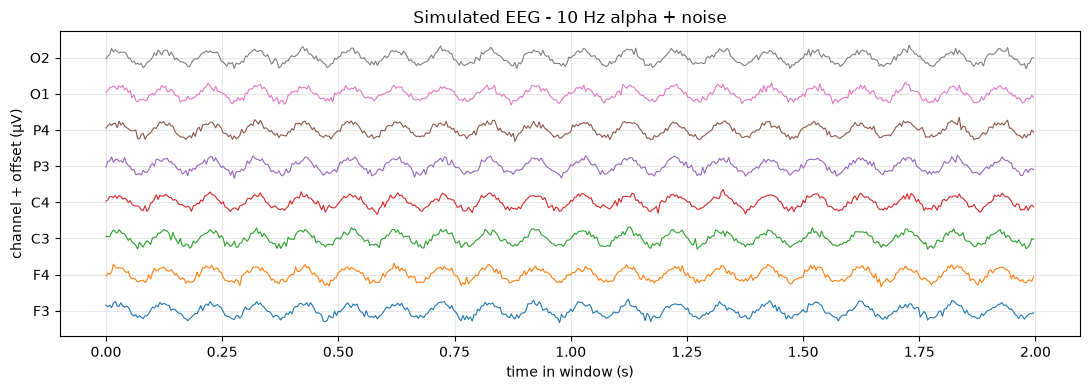

In [7]:
w = last_window
if w is None:
    raise RuntimeError("No full window captured - run the previous cell again")

t = np.arange(w.shape[1]) / MONTAGE.sfreq
offsets = np.arange(w.shape[0])[:, None] * 100.0  # 100 uV vertical spacing

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, (w - w.mean(axis=1, keepdims=True) + offsets).T, linewidth=0.8)
ax.set_xlabel("time in window (s)")
ax.set_ylabel("channel + offset (µV)")
ax.set_yticks(offsets[:, 0])
ax.set_yticklabels(MONTAGE.names)
ax.set_title("Simulated EEG - 10 Hz alpha + noise")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Takeaways

- `SimulatedDriver` implements the same `Driver` interface as `BrainAccessDriver`, so only the driver cell changes between simulation and hardware.
- Processors are read-only: the LSL chunk is published before they run and `window` is a copy. Use a buffer (like `cleaned`) or a second outlet to forward results.
- Always call `streamer.stop()` (the `finally` above does it), otherwise the background thread and the LSL outlet stay alive.
- The stream is advertised over LSL as `Simulated EEG`, type `EEG`, 8 channels at 250 Hz, so any LSL app can receive it.
